In [14]:
from game_agent_friendly import PolicyNetwork, Agent, generate
import torch
import numpy as np
%matplotlib widget

Testing the functioning of the policy network, with a totally random policy and checking that backpropagation via autodiff is working correctly.

In [15]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cpu device


In [16]:
# Initialise policy network
policy_model = PolicyNetwork().to(device)
# Initialise agent using the policy network and the device the agent will use for training:
agent = Agent(policy_model, [], device)
# Initialise start state of the game:
state_0 = np.array([[0 , 0 , 0 , 0] , [0 , 2 , 0 , 0] , [0 , 0 , 2 , 0 ] , [0 , 0 ,0 , 0]])
# Generate an episode of experience: 
episode = generate(state_0 , agent, print_episode=True)

up
[[0 2 2 0]
 [2 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]
left
[[4 4 0 0]
 [2 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]
up
[[4 4 0 0]
 [2 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]
down
[[0 0 0 2]
 [0 0 0 0]
 [4 0 0 0]
 [2 4 0 0]]
up
[[4 4 0 2]
 [2 0 0 2]
 [0 0 0 0]
 [0 0 0 0]]
up
[[4 4 2 4]
 [2 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]
down
[[0 0 0 0]
 [0 0 2 0]
 [4 0 0 0]
 [2 4 2 4]]
right
[[0 4 0 0]
 [0 0 0 2]
 [0 0 0 4]
 [2 4 2 4]]
up
[[2 8 2 2]
 [0 0 0 8]
 [0 0 2 0]
 [0 0 0 0]]
down
[[0 0 0 0]
 [0 0 0 0]
 [2 0 0 2]
 [2 8 4 8]]
up
[[4 8 4 2]
 [2 0 0 8]
 [0 0 0 0]
 [0 0 0 0]]
down
[[0 0 2 0]
 [0 0 0 0]
 [4 0 0 2]
 [2 8 4 8]]
right
[[0 0 0 2]
 [0 0 0 0]
 [0 2 4 2]
 [2 8 4 8]]
left
[[2 0 0 0]
 [0 0 0 2]
 [2 4 2 0]
 [2 8 4 8]]
right
[[0 0 0 2]
 [2 0 0 2]
 [0 2 4 2]
 [2 8 4 8]]
right
[[0 0 2 2]
 [0 0 0 4]
 [0 2 4 2]
 [2 8 4 8]]
up
[[2 2 2 2]
 [0 8 8 4]
 [0 0 0 2]
 [0 0 2 8]]
up
[[2 2 2 2]
 [0 8 8 4]
 [0 2 2 2]
 [0 0 0 8]]
right
[[ 0  0  4  4]
 [ 0  0 16  4]
 [ 2  0  2  4]
 [ 0  0  0  8]]
right
[[ 0  0  0  8]
 [ 0  0 16  4]
 [ 0  2  

Text(0.5, 1.0, 'Reward')

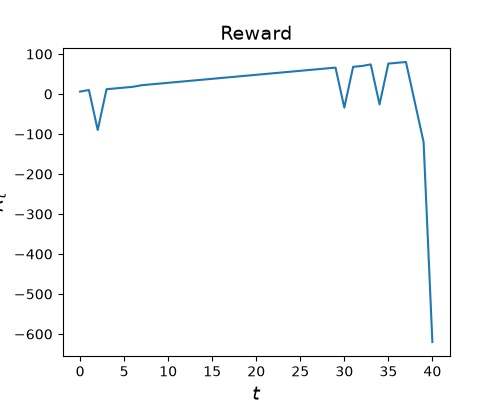

In [17]:
states , actions, rewards = episode
# Print Rewards over time: 
import matplotlib.pyplot as plt

fig , ax = plt.subplots(figsize = (5 , 4)) 
ax.plot(rewards)
ax.set_xlabel(r'$t$', fontsize = 14)
ax.set_ylabel(r'$R_{t}$' , fontsize = 14)
ax.set_title('Reward' , fontsize = 14)

In [18]:
np.max(states)

np.int64(64)

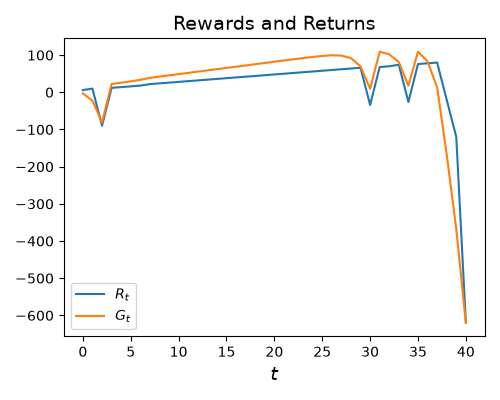

In [19]:
def G_t(t, rewards, episode_length, gamma): 
    '''
    Computes return in state at time t
    '''
    d = np.array([gamma**i for i in range(episode_length - t)])
    r = rewards[t:]
    return d@r 

G = [G_t(t , rewards , len(rewards), 0.4) for t in range(len(rewards))]

fig , ax = plt.subplots(figsize = (5 , 4)) 
ax.plot(rewards, label = r'$R_{t}$')
ax.plot(G , label = r'$G_{t}$')
ax.set_xlabel(r'$t$', fontsize = 14)
ax.set_title('Rewards and Returns' , fontsize = 14)
ax.legend() 
plt.tight_layout()

Attempting to implement reinforce gradients also: 

In [20]:
# Inspecting the policy networks weights and biases:
for name, param in PolicyNetwork().named_parameters():
    print(f"Layer: {name} | Size: {param.size()} | Values : {param[:2]} \n")

Layer: linear_relu_softmax.0.weight | Size: torch.Size([10, 16]) | Values : tensor([[ 0.0677,  0.2327,  0.0678, -0.0677,  0.1367, -0.0905, -0.2422, -0.0269,
         -0.0811, -0.1126, -0.1255,  0.0505,  0.2093, -0.1994,  0.0051,  0.0378],
        [-0.1121,  0.1578,  0.0283, -0.1780,  0.2450, -0.1713, -0.2492, -0.1365,
          0.1227,  0.2186, -0.1808, -0.1118,  0.2460, -0.1150, -0.1751, -0.1314]],
       grad_fn=<SliceBackward0>) 

Layer: linear_relu_softmax.0.bias | Size: torch.Size([10]) | Values : tensor([-0.1876,  0.1483], grad_fn=<SliceBackward0>) 

Layer: linear_relu_softmax.2.weight | Size: torch.Size([6, 10]) | Values : tensor([[-0.0014,  0.0916, -0.0149, -0.0831, -0.1602,  0.3014, -0.2409,  0.0767,
         -0.1482,  0.1377],
        [ 0.2306,  0.0334, -0.1110,  0.2880, -0.1919,  0.2079,  0.3103,  0.1173,
          0.0056, -0.0159]], grad_fn=<SliceBackward0>) 

Layer: linear_relu_softmax.2.bias | Size: torch.Size([6]) | Values : tensor([0.1810, 0.0452], grad_fn=<SliceBackwar

In [21]:
# Compiling vector of logits:
episode_logits = agent.logits
print(episode_logits)
# Inspecting the grad function of each logit obtained in the episode: 
test_grad = episode_logits[0].grad_fn
# Tracing the autograd graph back to its root:
print(test_grad.next_functions[0])
print(test_grad.next_functions[0][0].next_functions[0][0])
print(test_grad.next_functions[0][0].next_functions[0][0].next_functions[0][0])
print(test_grad.next_functions[0][0].next_functions[0][0].next_functions[0][0].next_functions[0][0])



[tensor(-1.4751, grad_fn=<SelectBackward0>), tensor(-1.8095, grad_fn=<SelectBackward0>), tensor(-1.8547, grad_fn=<SelectBackward0>), tensor(-0.8540, grad_fn=<SelectBackward0>), tensor(-1.7104, grad_fn=<SelectBackward0>), tensor(-1.9250, grad_fn=<SelectBackward0>), tensor(-0.8877, grad_fn=<SelectBackward0>), tensor(-1.1933, grad_fn=<SelectBackward0>), tensor(-1.7068, grad_fn=<SelectBackward0>), tensor(-0.6001, grad_fn=<SelectBackward0>), tensor(-1.1083, grad_fn=<SelectBackward0>), tensor(-0.4831, grad_fn=<SelectBackward0>), tensor(-1.3462, grad_fn=<SelectBackward0>), tensor(-2.0053, grad_fn=<SelectBackward0>), tensor(-1.3084, grad_fn=<SelectBackward0>), tensor(-1.2372, grad_fn=<SelectBackward0>), tensor(-1.2347, grad_fn=<SelectBackward0>), tensor(-1.2432, grad_fn=<SelectBackward0>), tensor(-1.2478, grad_fn=<SelectBackward0>), tensor(-1.0749, grad_fn=<SelectBackward0>), tensor(-1.2876, grad_fn=<SelectBackward0>), tensor(-1.0797, grad_fn=<SelectBackward0>), tensor(-1.1258, grad_fn=<Select

In [22]:
ep_logits_tensor = torch.stack(episode_logits)
print(ep_logits_tensor)
print(ep_logits_tensor.grad_fn.next_functions[0][0])
print(ep_logits_tensor.grad_fn.next_functions[0][0].next_functions[0][0])
print(ep_logits_tensor.grad_fn.next_functions[0][0].next_functions[0][0].next_functions[0][0])
print(ep_logits_tensor.grad_fn.next_functions[0][0].next_functions[0][0].next_functions[0][0].next_functions[0][0])
print(ep_logits_tensor.grad_fn.next_functions[0][0].next_functions[0][0].next_functions[0][0].next_functions[0][0].next_functions[0][0])

tensor([-1.4751, -1.8095, -1.8547, -0.8540, -1.7104, -1.9250, -0.8877, -1.1933,
        -1.7068, -0.6001, -1.1083, -0.4831, -1.3462, -2.0053, -1.3084, -1.2372,
        -1.2347, -1.2432, -1.2478, -1.0749, -1.2876, -1.0797, -1.1258, -1.8782,
        -1.9259, -0.3905, -1.4601, -1.4672, -0.5807, -1.0615, -1.1036, -1.4085,
        -1.4441, -1.2369, -1.2104, -0.9281, -1.4281, -0.5262, -1.1428, -1.1967,
        -1.1967], grad_fn=<StackBackward0>)


In [23]:
# Return tensor: 
return_tensor = torch.tensor(G, dtype = torch.float32 , device = device, requires_grad = False)
print(return_tensor)

tensor([  -2.9723,  -22.4308,  -81.0770,   22.3076,   25.7689,   29.4222,
          33.5556,   38.8889,   42.2222,   45.5556,   48.8889,   52.2222,
          55.5555,   58.8889,   62.2222,   65.5554,   68.8886,   72.2215,
          75.5538,   78.8844,   82.2111,   85.5278,   88.8194,   92.0486,
          95.1215,   97.8038,   99.5095,   98.7737,   91.9343,   69.8358,
           9.5896,  108.9741,  102.4352,   81.0879,   17.7197,  109.2992,
          83.2480,   13.1200, -167.2000, -368.0000, -620.0000])


In [24]:
# REINFORCE Loss: 
reinf_loss = -return_tensor.dot(ep_logits_tensor)
print(reinf_loss)
print(reinf_loss.grad_fn.next_functions[0][0].next_functions[1][0])


tensor(1286.4707, grad_fn=<NegBackward0>)


In [25]:
# Backpropagating gradient using autodiff : 
reinf_loss.backward()

In [26]:
# Checking grads were passed through each parameter correctly: 
for name, param in policy_model.named_parameters(): 
    print('Name of parameter:', name)
    print('Gradient of parameter:', param.grad)

Name of parameter: linear_relu_softmax.0.weight
Gradient of parameter: tensor([[-9.7372e+01, -7.8454e+01,  1.4848e+01, -3.1754e+01, -5.4591e+01,
         -2.0702e+01,  7.7485e+01,  2.5826e+02, -2.0655e+01,  3.5290e+01,
          2.0769e+02,  3.5633e+02,  6.3182e+01,  1.9055e+02,  4.3819e+02,
          1.9620e+02],
        [-1.9713e+01, -6.8777e+01, -6.7355e+01,  5.7260e+00, -2.1052e+01,
         -1.8986e+01,  2.6726e+01, -2.9324e+01,  7.5047e+01,  6.5310e+01,
          1.5476e+01,  1.5789e+01,  3.5676e+01,  1.1788e+02,  1.1496e+02,
          1.3426e+02],
        [ 4.7114e+00, -9.3915e+01, -9.0397e+01, -6.3485e+01,  1.7823e-01,
         -8.1739e+01, -1.6639e+02, -7.4453e+01,  1.9445e+00,  2.6266e+01,
         -5.7921e+01, -1.3403e+02, -3.8145e+01,  4.4538e+00, -5.9949e-01,
         -7.3828e+01],
        [-2.7502e+01, -5.1953e+01, -2.6452e+01, -9.3189e+01, -8.8772e+00,
          1.3711e+02,  6.8340e+01,  6.8139e+01,  8.9095e+00,  1.8429e+02,
          1.0425e+02, -7.2015e+01,  6.6310e+01

In [31]:
(G - np.mean(G))/(np.std(G) +1e-8)

array([-2.15852650e-01, -3.63816058e-01, -8.09765175e-01, -2.36229889e-02,
        2.69719714e-03,  3.04773627e-02,  6.19074768e-02,  1.02462463e-01,
        1.27809328e-01,  1.53156193e-01,  1.78503054e-01,  2.03849907e-01,
        2.29196740e-01,  2.54543523e-01,  2.79890182e-01,  3.05236529e-01,
        3.30582098e-01,  3.55925720e-01,  3.81264475e-01,  4.06591064e-01,
        4.31887235e-01,  4.57107365e-01,  4.82137389e-01,  5.06692150e-01,
        5.30058753e-01,  5.50454960e-01,  5.63425180e-01,  5.57830428e-01,
        5.05823251e-01,  3.37785006e-01, -1.20330904e-01,  6.35394300e-01,
        5.85672031e-01,  4.23346059e-01, -5.85094695e-02,  6.37866688e-01,
        4.39771802e-01, -9.34857118e-02, -1.46464980e+00, -2.99154503e+00,
       -4.90776813e+00])